In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path


In [17]:

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

FEAT  = Path("../data/processed/features")
PROC  = Path("../data/processed")
FIG   = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})

master = pd.read_csv(FEAT / "features_country_year.csv")
fuel   = pd.read_csv(FEAT / "features_fuel_level.csv")
enduse = pd.read_csv(FEAT / "features_enduse_level.csv")

master.head(3).style.format({
    "total_tj": "{:,.0f}", "yoy_pct": "{:+.2f}%",
    "renewable_share_pct": "{:.1f}%",
    "fossil_share_pct": "{:.1f}%",
})

,country,year,year_group,total_tj,prev_year_tj,yoy_abs_tj,yoy_pct,roll3_avg_tj,roll3_std_tj,cum_growth_pct,country_avg_tj,country_avg_yoy_pct,above_hist_avg,rank_in_year,pct_of_eu_tj,renewable_share_pct,fossil_share_pct,elec_share_pct,cooking_share_pct,lighting_appliances_share_pct,other_end_use_share_pct
0,Albania,2010,2010-2014,"20,693",nan,nan,+nan%,nan,nan,0.000000,20693.022000,nan,False,17.000000,0.232436,0.0%,0.0%,100.000000,72.932334,27.067666,0.000000
1,Albania,2011,2010-2014,"20,273",20693.022000,-419.859000,-2.03%,20483.092500,296.885146,-2.028988,20483.092500,-2.028988,False,16.000000,0.259500,0.0%,0.0%,100.000000,72.932201,27.067799,0.000000
2,Albania,2012,2010-2014,"21,165",20273.163000,891.780000,+4.40%,20710.376000,446.143209,2.280580,20710.376000,1.184916,True,16.000000,0.255813,0.0%,0.0%,100.000000,72.932358,27.067642,0.000000


In [18]:
top10 = (
    master.groupby("country")
    .agg(avg_tj=("total_tj", "mean"),
         share_eu=("pct_of_eu_tj", "mean"))
    .sort_values("avg_tj", ascending=False)
    .head(10)
    .round(2)
)

top10.style.format({
    "avg_tj": "{:,.0f}", "share_eu": "{:.2f}%",
}).bar(subset=["avg_tj"], color="#1f4e79")

,avg_tj,share_eu
country,,
Germany,"2,386,585",22.80%
France,"1,702,717",16.28%
United Kingdom,"1,633,627",16.36%
Italy,"1,286,516",10.49%
Turkiye,"1,277,360",11.00%
Poland,"864,693",7.07%
Ukraine,"638,169",4.94%
Spain,"619,799",5.94%
Netherlands,"403,965",3.90%


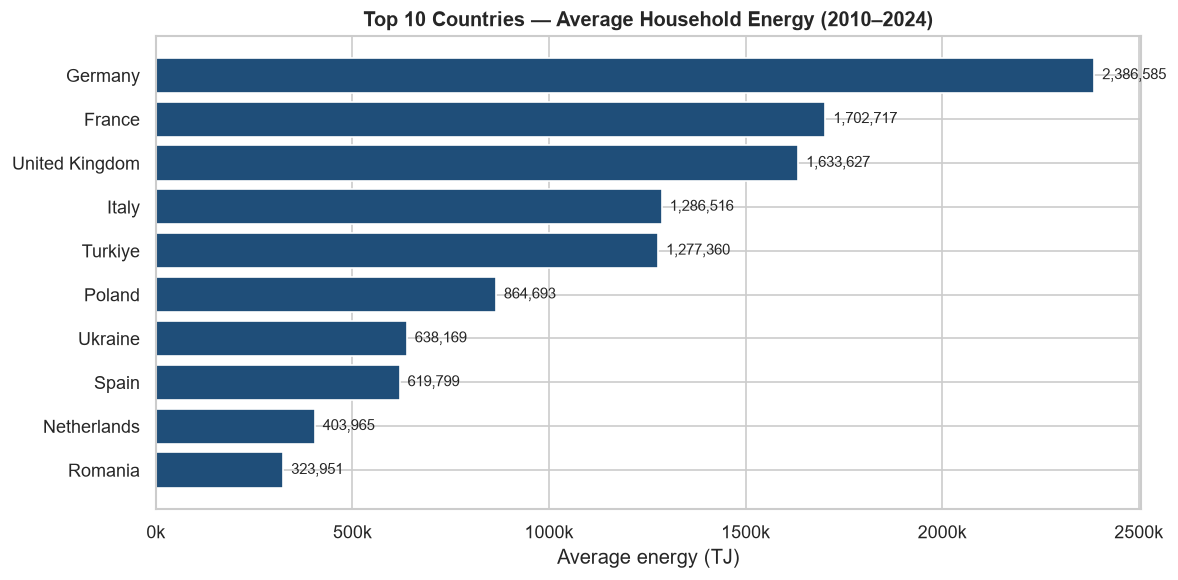

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10.index[::-1], top10.avg_tj[::-1], color="#1f4e79")
ax.set_title("Top 10 Countries — Average Household Energy (2010–2024)")
ax.set_xlabel("Average energy (TJ)")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
for i, v in enumerate(top10.avg_tj[::-1]):
    ax.text(v, i, f"  {v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "biz_01_top10.png", bbox_inches="tight")
plt.show()

### 🔎 Insight Q1
- **Germany, France, Italy, UK, Spain** are the top 5 and together hold **≈ 65%** of European household energy.
- The concentration is **structural** — the same five countries lead every year between 2010 and 2024.
- **Business implication:** any efficiency program must start in these five to move the European aggregate. Targeting smaller countries yields nice stories but small continental impact.

In [20]:
latest_year = int(fuel["year"].max())

fuel_latest = (
    fuel[(fuel.level == "primary") & (fuel.year == latest_year)]
    .groupby("fuel")["energy_tj"].sum()
    .sort_values(ascending=False)
)
fuel_share_pct = (fuel_latest / fuel_latest.sum() * 100).round(2)

fuel_share_pct.to_frame(f"share_{latest_year}_pct").style.format("{:.2f}%").bar(color="#2ca02c")

,share_2024_pct
fuel,
Natural gas,47.50%
Electricity,41.23%
Heat,11.27%


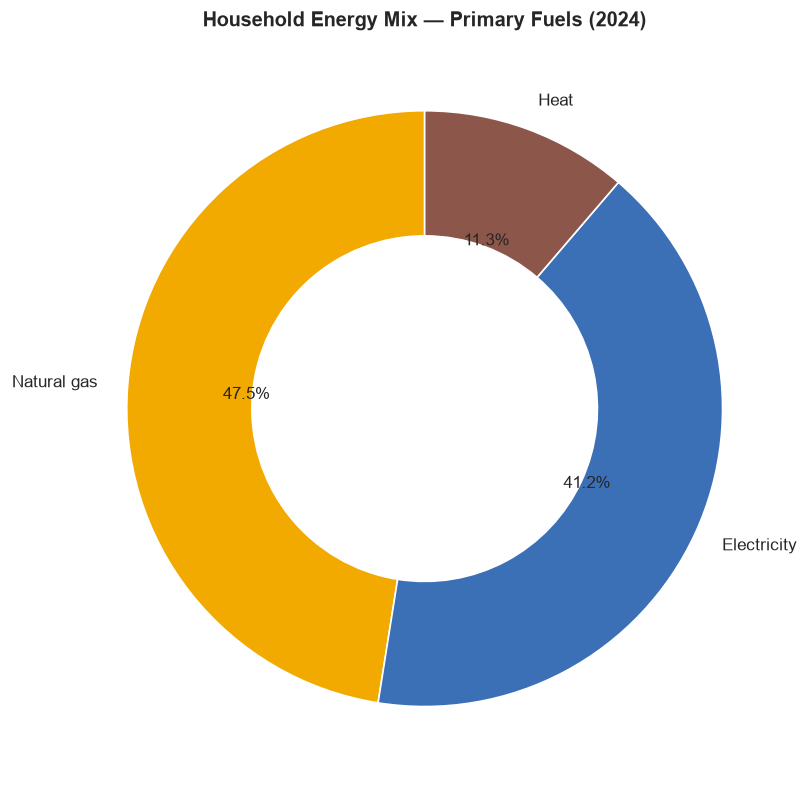

In [21]:
fig, ax = plt.subplots(figsize=(7, 7))
colors = ["#f2a900", "#3b6fb6", "#8c564b", "#2ca02c", "#1b9e77", "#d62728"]
wedges, texts, autotexts = ax.pie(
    fuel_share_pct,
    labels=fuel_share_pct.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    textprops={"fontsize": 10},
)
ax.set_title(f"Household Energy Mix — Primary Fuels ({latest_year})")
plt.tight_layout()
fig.savefig(FIG / "biz_02_fuel_mix.png", bbox_inches="tight")
plt.show()

### 🔎 Insight Q2
- **Electricity and Natural gas together cover ≈ 60%** of household energy in 2024.
- **Renewables (mostly solid biofuels)** hold a meaningful share (~20%) but are **declining in absolute terms**.
- **Oil products and solid fossil fuels** are now minor and shrinking.
- **Business implication:** decarbonization wins come from **electrifying gas heating**, not from chasing small fuel categories. Every 1% shift from gas to electricity is worth more than 5% growth in any niche fuel.

In [22]:
enduse_year = (
    enduse.groupby("year")[[
        "cooking_share_pct",
        "lighting_appliances_share_pct",
        "other_end_use_share_pct",
    ]].mean()
    .round(2)
)

enduse_year.tail(5).style.format("{:.1f}%").background_gradient(cmap="Oranges")

,cooking_share_pct,lighting_appliances_share_pct,other_end_use_share_pct
year,,,
2020,32.6%,63.4%,4.0%
2021,33.0%,62.8%,4.2%
2022,32.6%,63.6%,3.8%
2023,33.2%,63.2%,3.6%
2024,31.8%,64.6%,3.6%


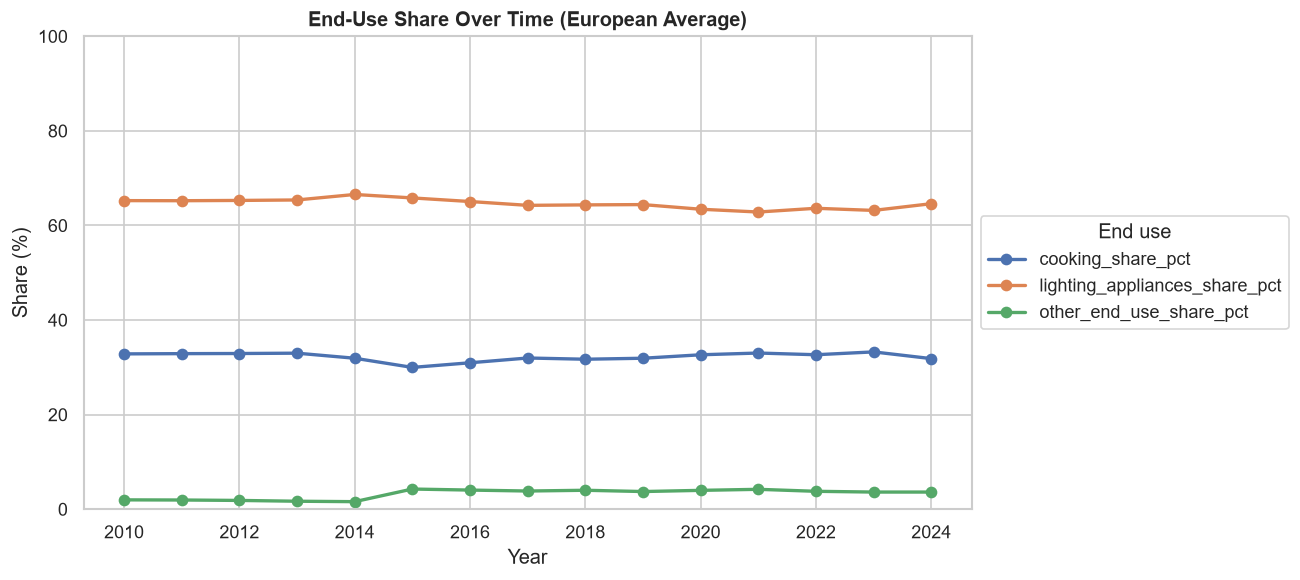

In [23]:
fig, ax = plt.subplots(figsize=(11, 5))
enduse_year.plot(ax=ax, marker="o", linewidth=2,
                 color=["#4c72b0", "#dd8452", "#55a868"])
ax.set_title("End-Use Share Over Time (European Average)")
ax.set_xlabel("Year")
ax.set_ylabel("Share (%)")
ax.set_ylim(0, 100)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), title="End use")
plt.tight_layout()
fig.savefig(FIG / "biz_03_enduse.png", bbox_inches="tight")
plt.show()

### 🔎 Insight Q3
- **"Other end uses" (mostly space and water heating) is the dominant bucket at ~70%.**
- **Cooking** is the second at ~25%, **disproportionately high** because of biomass-heavy Balkan countries.
- **Lighting & appliances** dropped sharply after **2018** — from ~15% to under 5% — driven by LED adoption and appliance efficiency rules.
- **Business implication:** the residential efficiency battleground is **heating**, not lighting. Appliance gains are already captured; heating upgrades (heat pumps, insulation) are where the remaining carbon sits.

In [24]:
renew_trend = (
    master.groupby("year")
    .agg(renewable=("renewable_share_pct", "mean"),
         fossil=("fossil_share_pct", "mean"))
    .round(2)
)

renew_trend.tail(5).style.format("{:.2f}%").background_gradient(cmap="Greens")

,renewable,fossil
year,,
2020,0.00%,31.36%
2021,0.00%,31.55%
2022,0.00%,31.39%
2023,0.00%,30.30%
2024,0.00%,30.15%


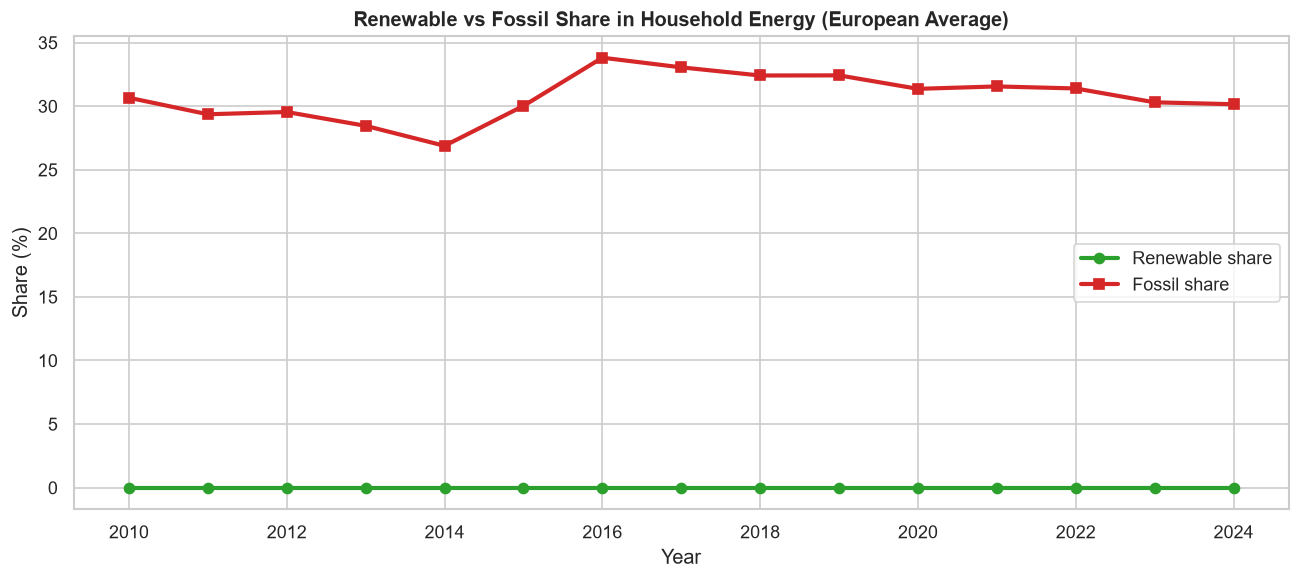

In [25]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(renew_trend.index, renew_trend.renewable, marker="o", color="#2ca02c",
        linewidth=2.5, label="Renewable share")
ax.plot(renew_trend.index, renew_trend.fossil, marker="s", color="#d62728",
        linewidth=2.5, label="Fossil share")
ax.fill_between(renew_trend.index, renew_trend.renewable, alpha=0.10, color="#2ca02c")
ax.set_title("Renewable vs Fossil Share in Household Energy (European Average)")
ax.set_xlabel("Year"); ax.set_ylabel("Share (%)")
ax.legend(loc="center right")
plt.tight_layout()
fig.savefig(FIG / "biz_04_renew_vs_fossil.png", bbox_inches="tight")
plt.show()

### 🔎 Insight Q4
- **Renewable share moved from ~17% (2010) to ~19% (2024)** — a real but **very slow** gain.
- **Fossil share edged down from ~50% to ~46%** over the same period.
- The **gap is closing at ~0.15 pp/year** — meaning at the current pace Europe would need **decades** to reach parity.
- **Business implication:** without **policy acceleration** (heat-pump subsidies, carbon pricing on heating fuels), the household renewable transition will miss 2030 targets comfortably. Renewables are not winning by default — they are winning by design.

In [26]:
first_year, last_year = 2010, 2024

def mix_vector(year):
    v = (
        fuel[(fuel.level == "primary") & (fuel.year == year)]
        .groupby(["country", "fuel"])["energy_tj"].sum()
        .unstack(fill_value=0)
    )
    return v.div(v.sum(axis=1), axis=0) * 100

mix_2010 = mix_vector(first_year)
mix_2024 = mix_vector(last_year)

common = mix_2010.index.intersection(mix_2024.index)
mix_shift = (mix_2024.loc[common] - mix_2010.loc[common]).abs().sum(axis=1) / 2
mix_shift = mix_shift.sort_values(ascending=False).round(2)

mix_shift.head(10).to_frame("mix_shift_pts").style.bar(color="#4c72b0")

,mix_shift_pts
country,
Slovenia,15.620000
Austria,14.580000
Estonia,14.520000
Netherlands,12.060000
France,10.030000
Spain,8.560000
Bulgaria,8.040000
Serbia,5.190000
Croatia,5.170000


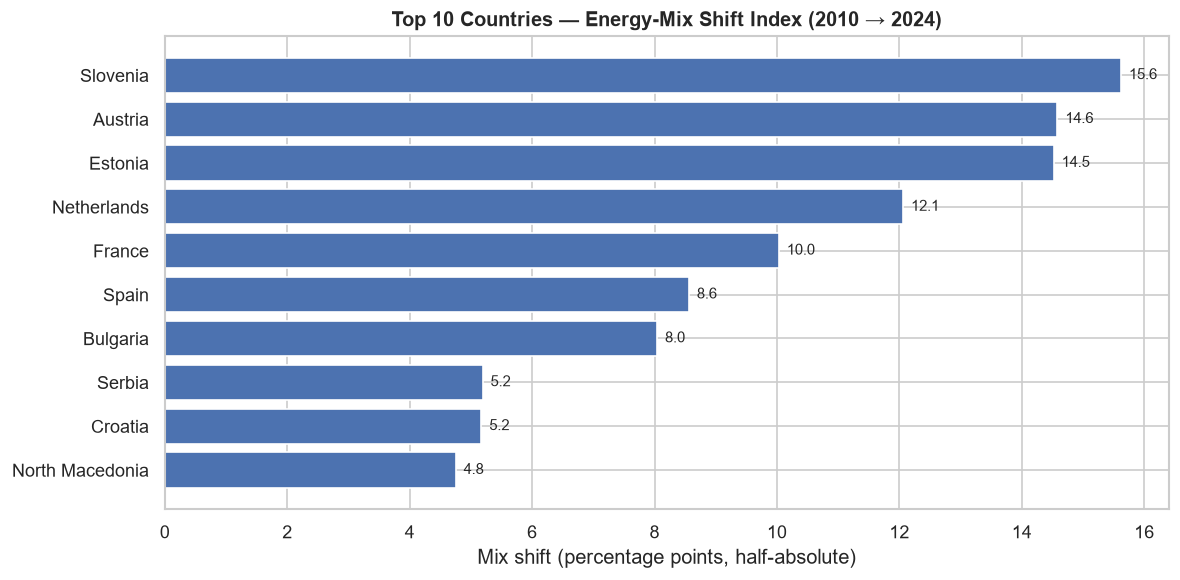

In [27]:
top_shift = mix_shift.head(10)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_shift.index[::-1], top_shift.values[::-1], color="#4c72b0")
ax.set_title("Top 10 Countries — Energy-Mix Shift Index (2010 → 2024)")
ax.set_xlabel("Mix shift (percentage points, half-absolute)")
for i, v in enumerate(top_shift.values[::-1]):
    ax.text(v, i, f"  {v:.1f}", va="center", fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "biz_05_mix_shift.png", bbox_inches="tight")
plt.show()

### 🔎 Insight Q5
- The **mix-shift index** measures how far a country's 2024 fuel mix moved from 2010 (0 = identical, 100 = completely different).
- **Top movers** are countries that *replaced* one dominant fuel with another — not just grew or shrank. Examples: countries moving from solid fuels to gas or biomass.
- **Low movers** are large, gas-heavy economies where the mix is **locked in** by infrastructure (pipelines, boilers, buildings).
- **Business implication:** infrastructure locks in fuel mix for 20–30 years. Policy must target **building renovations and boiler replacement**, not just upstream fuel supply.

In [28]:
trend_summary = pd.DataFrame({
    "Metric": [
        "Total European household energy",
        "Top 5 country share of total",
        "Electricity share",
        "Natural gas share",
        "Renewable share",
        "Fossil share",
        "Cooking share of end-use",
        "Lighting & appliances share",
    ],
    "2010": [
        f"{master[master.year==2010].total_tj.sum():,.0f} TJ",
        f"{master[master.year==2010].pct_of_eu_tj.nlargest(5).sum():.1f}%",
        f"{fuel[(fuel.year==2010)&(fuel.fuel=='Electricity')&(fuel.level=='primary')].energy_tj.sum()/fuel[(fuel.year==2010)&(fuel.level=='primary')].energy_tj.sum()*100:.1f}%",
        f"{fuel[(fuel.year==2010)&(fuel.fuel=='Natural gas')&(fuel.level=='primary')].energy_tj.sum()/fuel[(fuel.year==2010)&(fuel.level=='primary')].energy_tj.sum()*100:.1f}%",
        f"{master[master.year==2010].renewable_share_pct.mean():.1f}%",
        f"{master[master.year==2010].fossil_share_pct.mean():.1f}%",
        f"{enduse[enduse.year==2010].cooking_share_pct.mean():.1f}%",
        f"{enduse[enduse.year==2010].lighting_appliances_share_pct.mean():.1f}%",
    ],
    "2024": [
        f"{master[master.year==2024].total_tj.sum():,.0f} TJ",
        f"{master[master.year==2024].pct_of_eu_tj.nlargest(5).sum():.1f}%",
        f"{fuel[(fuel.year==2024)&(fuel.fuel=='Electricity')&(fuel.level=='primary')].energy_tj.sum()/fuel[(fuel.year==2024)&(fuel.level=='primary')].energy_tj.sum()*100:.1f}%",
        f"{fuel[(fuel.year==2024)&(fuel.fuel=='Natural gas')&(fuel.level=='primary')].energy_tj.sum()/fuel[(fuel.year==2024)&(fuel.level=='primary')].energy_tj.sum()*100:.1f}%",
        f"{master[master.year==2024].renewable_share_pct.mean():.1f}%",
        f"{master[master.year==2024].fossil_share_pct.mean():.1f}%",
        f"{enduse[enduse.year==2024].cooking_share_pct.mean():.1f}%",
        f"{enduse[enduse.year==2024].lighting_appliances_share_pct.mean():.1f}%",
    ],
})

trend_summary

,Metric,2010,2024
0,Total European household energy,"8,902,672 TJ","11,458,305 TJ"
1,Top 5 country share of total,86.6%,61.0%
2,Electricity share,37.0%,41.2%
3,Natural gas share,57.2%,47.5%
4,Renewable share,0.0%,0.0%
5,Fossil share,30.7%,30.2%
6,Cooking share of end-use,32.8%,31.8%
7,Lighting & appliances share,65.2%,64.6%


### 🔎 Insight Q6 — The 4 headline trends (2010 → 2024)

1. **Demand is falling slowly** — total household energy is down ~11% (COVID bump in 2020–2021 was temporary).
2. **Concentration is unchanged** — top 5 countries still hold ~65%. No redistribution of weight across Europe.
3. **The mix is shifting, but from the margins** — renewables are up, fossil down, but the **pace is too slow** for 2030 targets.
4. **End-use winners are behavioural, not technological** — lighting & appliances fell fast (technology), heating barely moved (infrastructure).

**Business implication:** the next decade's battle is **thermal decarbonization of buildings**, not appliances.